# 02 · Features and baselines

**Goal (Phase 6, step 6.10):** look at the model feature table and set the scores every model in Phase 7 must beat.

- Each row is a forecast made at the end of month *t* for month *t+1*, per user and **series**
  (`income`, `expenses`, `expenses:<Category>`).
- Features only use months ≤ *t* (checked by the leakage test, step 6.6); calendar features describe the target month.
- Baselines are scored with the rolling-origin backtest (step 6.7): train on the past, test on the next month, 23 test months.

> Data is **synthetic** (300 generated users). Rebuild with `python pipelines/run_ingestion.py` then `python pipelines/run_training.py`.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "config.yaml").exists())
sys.path.insert(0, str(ROOT))
from src.utils.helpers import load_config, resolve_path
from src.training.train_baselines import evaluate

config = load_config()
features = pd.read_parquet(resolve_path(config["paths"]["data_processed"]) / config["processed"]["features_file"])
for column in ("month", "target_month"):
    features[column] = features[column].dt.to_period("M")
monthly = pd.read_parquet(resolve_path(config["paths"]["data_processed"]) / config["processed"]["monthly_file"])
users = pd.read_csv(resolve_path(config["paths"]["data_raw"]) / config["synthetic"]["users_file"])

FEATURES = ["lag_1", "lag_2", "lag_3", "lag_12", "roll_mean_3", "roll_mean_6", "roll_std_6", "history_months",
            "month_sin", "month_cos", "holidays", "working_days", "days_in_month", "fixed_share", "income_volatility"]
FEATURES += [c for c in ("inflation_de", "ecb_rate") if c in features]
plt.rcParams.update({"figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
                     "axes.edgecolor": "#e1e0d9", "axes.grid": True, "grid.color": "#e1e0d9",
                     "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold", "font.size": 10})
print(f"{len(features):,} rows · {features['user_id'].nunique()} users · {features['series'].nunique()} series · "
      f"{len(FEATURES)} features (macro: {'yes' if 'inflation_de' in features else 'not yet - no ECB cache'})")

129,600 rows · 300 users · 12 series · 15 features (macro: not yet - no ECB cache)


## 1. The feature table

In [2]:
print(sorted(features["series"].unique()))
example = features[(features["user_id"] == "user_001") & (features["series"] == "expenses:Groceries")]
display(example.iloc[11:15][["month", "target_month", "value", "target"] + FEATURES[:8]].round({c: 2 for c in ["value", "target"] + FEATURES[:8]}))

missing = features[FEATURES].isna().mean().sort_values(ascending=False)
print("Share of rows where a feature is empty (always early months without enough history):")
print((missing[missing > 0] * 100).round(1).astype(str).add(" %").to_string())
usable = features.dropna(subset=["target", "lag_12"])
print(f"Rows with a target and a full year of history: {len(usable):,}")

['expenses', 'expenses:Dining', 'expenses:Groceries', 'expenses:Health', 'expenses:Leisure', 'expenses:Other', 'expenses:Rent', 'expenses:Shopping', 'expenses:Subscriptions', 'expenses:Transport', 'expenses:Utilities', 'income']


,month,target_month,value,target,lag_1,lag_2,lag_3,lag_12,roll_mean_3,roll_mean_6,roll_std_6,history_months
83,2024-09,2024-10,227.48,242.77,227.48,261.54,244.17,251.85,244.40,240.05,12.70,12
84,2024-10,2024-11,242.77,199.31,242.77,227.48,261.54,207.31,243.93,242.64,11.04,13
85,2024-11,2024-12,199.31,259.42,199.31,242.77,227.48,272.36,223.19,235.59,20.92,14
86,2024-12,2025-01,259.42,234.31,259.42,199.31,242.77,229.72,233.83,239.12,23.13,15


Share of rows where a feature is empty (always early months without enough history):
lag_12               30.6 %
roll_mean_6          13.9 %
roll_std_6           13.9 %
income_volatility    13.9 %
lag_3                 5.6 %
fixed_share           5.6 %
roll_mean_3           5.6 %
lag_2                 2.8 %
Rows with a target and a full year of history: 86,400


## 2. Which features move with the target?
Spearman rank correlation with next month's value, per series group (rows with a full year of history).

In [3]:
group = usable["series"].where(usable["series"].isin(["income", "expenses"]), "category")
corr = pd.DataFrame({g: part[FEATURES].corrwith(part["target"], method="spearman")
                     for g, part in usable.groupby(group)})[["income", "expenses", "category"]]
display(corr.round(2).style.background_gradient(cmap="Blues", vmin=0, vmax=1))

,income,expenses,category
lag_1,0.770000,0.680000,0.750000
lag_2,0.770000,0.660000,0.750000
lag_3,0.770000,0.850000,0.830000
lag_12,0.760000,0.910000,0.870000
roll_mean_3,0.810000,0.810000,0.790000
roll_mean_6,0.830000,0.820000,0.790000
roll_std_6,-0.030000,0.390000,-0.020000
history_months,0.050000,0.070000,0.020000
month_sin,0.010000,-0.030000,-0.010000
month_cos,-0.010000,-0.060000,-0.010000


## 3. Baselines on the backtest
The three simple forecasts, scored on every test month and on unseen users with short histories.

In [4]:
results = evaluate(features, users=users, monthly=monthly)
fmt = {"mae": "€{:,.2f}".format, "rmse": "€{:,.2f}".format, "smape": "{:.1f} %".format}
print(f"{results['test_months']} test months")
display(results["by_group"].style.format(fmt).hide(axis="index"))

23 test months


series_group,baseline,mae,rmse,smape,n
category,last_month,€83.39,€269.25,41.5 %,69000
category,mean_3,€67.51,€181.06,42.4 %,69000
category,same_month_last_year,€44.56,€119.81,32.8 %,69000
expenses,last_month,€544.02,€843.12,21.1 %,6900
expenses,mean_3,€405.87,€570.19,16.4 %,6900
expenses,same_month_last_year,€243.81,€381.48,10.7 %,6900
income,last_month,€547.28,"€1,537.67",18.6 %,6900
income,mean_3,€460.96,"€1,259.41",15.5 %,6900
income,same_month_last_year,€628.50,"€1,567.25",21.0 %,6900


In [5]:
by_type = results["by_archetype"].pivot_table(index=["series_group", "archetype"], columns="baseline", values="mae")
display(by_type.round(2).style.format("€{:,.2f}").highlight_min(axis=1, color="#cde2fb"))

In [6]:
new_users = results["new_users"].pivot_table(index="history_months", columns="baseline", values="mae")
print("MAE for users the model has never seen, by months of history:")
display(new_users.round(2).style.format("€{:,.2f}").highlight_min(axis=1, color="#cde2fb"))

MAE for users the model has never seen, by months of history:


baseline,last_month,mean_3,same_month_last_year
history_months,,,
3,€204.55,€147.35,€204.55
6,€204.55,€147.35,€204.55
12,€204.55,€147.35,€125.35


## 4. The bar to beat
Best baseline per series (also saved to `models/baseline_scores.json`).

series,baseline,mae,smape
expenses:Subscriptions,last_month,€0.00,0.0 %
expenses:Rent,last_month,€1.67,0.2 %
expenses:Utilities,mean_3,€1.86,1.3 %
expenses:Other,same_month_last_year,€3.28,2.5 %
expenses:Groceries,mean_3,€23.23,7.0 %
expenses:Health,mean_3,€44.28,117.0 %
expenses:Dining,mean_3,€48.10,37.0 %
expenses:Shopping,same_month_last_year,€80.26,46.7 %
expenses:Transport,same_month_last_year,€93.43,45.2 %
expenses:Leisure,same_month_last_year,€112.68,54.0 %


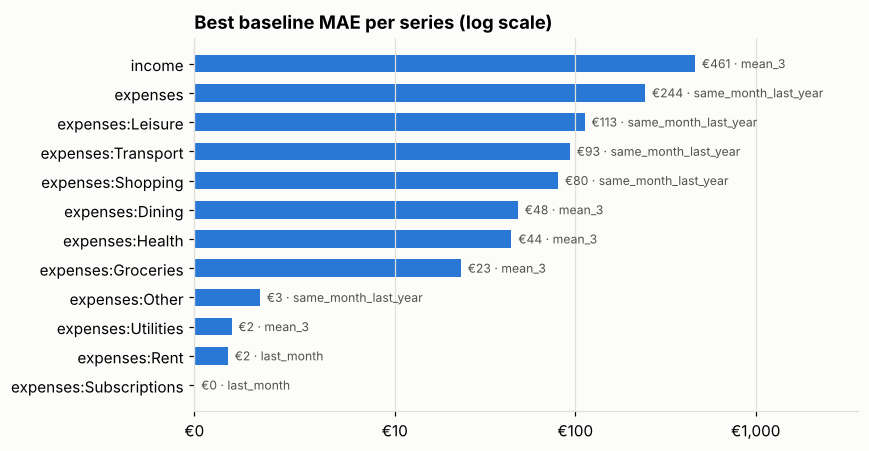

In [7]:
best = results["best_by_series"].sort_values("mae")
display(best.style.format(fmt).hide(axis="index"))

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(best["series"], best["mae"], color="#2a78d6", height=0.6)
for y, (value, name) in enumerate(zip(best["mae"], best["baseline"])):
    ax.text(value, y, f"  €{value:,.0f} · {name}", va="center", fontsize=8, color="#52514e")
ax.set_xscale("symlog", linthresh=10)
ax.set_xlim(0, best["mae"].max() * 8)
ax.xaxis.set_major_formatter(lambda v, _: f"€{v:,.0f}")
ax.set_title("Best baseline MAE per series (log scale)", loc="left")
ax.grid(axis="y", visible=False)
fig.tight_layout(); plt.show()

## 5. Findings: what Phase 7 has to beat

| # | Finding | Evidence | Consequence for the models |
|---|---|---|---|
| 1 | **History is the signal.** | Rank correlation with the target: 6-month mean 0.79–0.83, `lag_12` 0.76–0.91, `lag_1` 0.68–0.77. | Lags and rolling means are the core inputs; the model's job is to weigh them per series and user. |
| 2 | **Same-month-last-year matters most for spending.** | `lag_12` correlates 0.91 with total spending; it is the best baseline for total spending (MAE €244 vs €544 for "last month"). | Seasonality (December, summer, quarterly taxes) must be learned; a year of history is valuable. |
| 3 | **A quarterly rhythm shows up.** | For total spending `lag_3` (t−2, three months before the target) correlates 0.85 vs 0.68 for `lag_1` — the freelancers' quarterly tax prepayments. | The model can learn the cycle; a single baseline cannot. |
| 4 | **Calendar features are weak on their own.** | Month sine/cosine, holidays and working days correlate ≈ 0 with the target directly. | Expected: they only help in combination (e.g. *December* × *shopping*), which tree models like LightGBM can learn. Keep them, judge them by feature importance. |
| 5 | **Salaried income is already solved.** | "Last month" MAE: €9 salaried single, €13 family, €2 students. | No model will meaningfully beat this; the champion rule may keep the baseline here, which is an honest result. |
| 6 | **Freelancer income is the real challenge.** | Best baseline MAE €1,767 per month for freelancer income. | This is where `income_volatility`, `roll_std_6` and the quantile range (10th–90th percentile) earn their keep. |
| 7 | **New users are harder.** | Unseen users: best MAE €147 with 3 or 6 months of history, €125 with 12. | Cold-start note in the app; Phase 7 reports new-user scores separately. |

**Done-when check for Phase 6:** `features.parquet` from one call ✓ · leakage test passes ✓ · baseline MAE table ✓ (also in `models/baseline_scores.json`).